# Session 8: Multi-Agent Systems - Supervisor, Router

One agent with every tool works for small problems. As tools and responsibilities grow, a common design is several **specialist agents**, each with a few tools and a focused prompt, coordinated by a **supervisor** or a **router**.

Today we build both patterns in LangChain/LangGraph, **measure** what they cost compared with a single agent, and then meet a second framework, **AutoGen**, for comparison.

| Part | What we do |
|---|---|
| 0 | Setup: the bank database, read-only, and an LLM call counter |
| 1 | When one agent is not enough |
| 2 | Three specialist agents |
| 3 | Pattern A: a supervisor that calls specialists as tools |
| 4 | Pattern B: a router graph with parallel specialists (`Send`) |
| 5 | Single agent vs supervisor vs router: calls, tokens, time |
| 6 | Context between agents: what a specialist actually sees |

**Data:** `data/bank.db`

## Setup: run this cell first

Choose the provider and model in the cell below. The API key is **not** written here: it stays in the `.env` file in this folder, for example:

```
OPENROUTER_API_KEY=sk-or-v1-...
```

In [16]:
# ===================== SETUP: run this cell first =====================
PROVIDER = "openrouter"    # "openrouter", "gemini" or "openai"
MODEL = "gpt-4o-mini"                 # leave empty to use the default model below

import os
from dotenv import load_dotenv

# read the .env file in this folder (override=True picks up edits without restarting the kernel)
"""if not os.path.exists(".env"):
    raise FileNotFoundError("No .env file in this folder. Create it and add your API key.")"""
load_dotenv()

if PROVIDER == "openrouter":
    KEY_NAME = "OPENROUTER_API_KEY"
    MODEL = MODEL or "google/gemini-2.5-flash-lite"
    BASE_URL = "https://openrouter.ai/api/v1"
elif PROVIDER == "gemini":
    KEY_NAME = "GOOGLE_API_KEY"
    MODEL = MODEL or "gemini-2.5-flash-lite"
    BASE_URL = "https://generativelanguage.googleapis.com/v1beta/openai/"
elif PROVIDER == "openai":
    KEY_NAME = "OPENAI_API_KEY"
    MODEL = MODEL or "gpt-4.1-mini"
    BASE_URL = "https://api.openai.com/v1"
else:
    raise ValueError('PROVIDER must be "openrouter", "gemini" or "openai"')

API_KEY = os.getenv(KEY_NAME)
if not API_KEY:
    raise ValueError(f"{KEY_NAME} is missing. Add it to the .env file in this folder.")


def get_chat_model(temperature=0, **kwargs):
    """LangChain chat model for the chosen provider."""
    if PROVIDER == "openrouter":
        from langchain_openrouter import ChatOpenRouter
        return ChatOpenRouter(model=MODEL, api_key=API_KEY, base_url=BASE_URL, temperature=temperature, **kwargs)
    elif PROVIDER == "gemini":
        from langchain_google_genai import ChatGoogleGenerativeAI
        return ChatGoogleGenerativeAI(model=MODEL, api_key=API_KEY, temperature=temperature, **kwargs)
    else:
        from langchain_openai import ChatOpenAI
        return ChatOpenAI(model=MODEL, api_key=API_KEY, base_url=BASE_URL, temperature=temperature, **kwargs)


def get_openai_client():
    """Plain OpenAI SDK client pointed at the chosen provider. Returns (client, model)."""
    from openai import OpenAI
    return OpenAI(api_key=API_KEY, base_url=BASE_URL), MODEL


def show_config():
    """Print the settings without showing the full key."""
    print(f"provider : {PROVIDER}")
    print(f"model    : {MODEL}")
    print(f"key      : {KEY_NAME} = {API_KEY[:6]}...{API_KEY[-2:]} ({len(API_KEY)} chars)")
    print(f"endpoint : {BASE_URL}")


show_config()

provider : openrouter
model    : gpt-4o-mini
key      : OPENROUTER_API_KEY = sk-or-...1d (73 chars)
endpoint : https://openrouter.ai/api/v1


## Part 0: Setup

In [17]:
import json
import time
import sqlite3
import operator
from typing import Annotated, Literal, TypedDict
from importlib.metadata import version

for pkg in ["langchain", "langgraph", "autogen-agentchat", "autogen-ext"]:
    print(f"{pkg:18s} {version(pkg)}")

import pandas as pd
from pydantic import BaseModel, Field
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.callbacks import BaseCallbackHandler
from langchain.agents import create_agent
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langgraph.checkpoint.memory import InMemorySaver

llm = get_chat_model(temperature=0)

langchain          1.4.3
langgraph          1.2.14
autogen-agentchat  0.7.5
autogen-ext        0.7.5


In [18]:
from IPython.display import Image, display


def show_graph(graph):
    """Draw a compiled LangGraph graph (PNG via mermaid.ink, or Mermaid text if offline)."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

### Measuring cost: an LLM call counter

Multi-agent systems make **more** LLM calls than a single agent. To compare honestly we count them. A **callback handler** is notified by LangChain at every model call, including calls made **inside** other agents, because the callbacks in the config are passed down to every child run.

In [19]:
class CallCounter(BaseCallbackHandler):
    """Counts chat model calls and tokens for everything run with this callback."""

    def __init__(self):
        self.calls = 0
        self.tokens = 0

    def on_chat_model_start(self, serialized, messages, **kwargs):
        self.calls += 1

    def on_llm_end(self, response, **kwargs):
        for generation_list in response.generations:
            for generation in generation_list:
                usage = getattr(getattr(generation, "message", None), "usage_metadata", None)
                if usage:
                    self.tokens += usage["total_tokens"]


counter = CallCounter()
llm.invoke("Say hi in 3 words.", config={"callbacks": [counter]})
print("calls:", counter.calls, "| tokens:", counter.tokens)

calls: 1 | tokens: 19


### The bank system: read-only, bound to the logged-in customer

Same rules as Sessions 5 and 6: a **read-only** connection, and the customer id comes from **our code** (`LOGGED_IN`), never from the model.

In [20]:
DB_PATH = "../data/bank.db"
LOGGED_IN = "C1001"


def query(sql, params=()):
    with sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True) as con:
        return con.execute(sql, params).fetchall()


print(query("SELECT customer_id, name, city, segment FROM customers WHERE customer_id = ?", (LOGGED_IN,)))

[('C1001', 'Riya Sharma', 'Pune', 'retail')]


## Part 1: When one agent is not enough

Every tool's **name, description and argument schema** is sent to the model on **every** call. More tools = longer prompts = higher cost, and more chances to pick the wrong tool. We measure this at the end of Part 2, once the tools exist.

| Reason to split into several agents | Example |
|---|---|
| Too many tools for one prompt | 30 tools across accounts, loans, cards, investments |
| Different instructions per area | loans need compliance wording; cards need fraud steps |
| Different owners or teams | the cards team maintains its own agent and tests it alone |
| Different models per job | a cheap model for routing, a stronger one for analysis |

| Reason NOT to | |
|---|---|
| More LLM calls | the supervisor and each specialist all call the model |
| More latency | calls in sequence add up |
| Harder debugging | an answer passes through several agents |
| Lost context | a specialist only sees what it is sent (Part 6) |

**Rule of thumb:** start with one agent. Split only when you can name the problem the split solves.

**Analogy:** a bank branch. One clerk who handles everything is fast for simple requests. A big branch has an enquiry desk that sends you to the loans desk or the cards desk: each desk knows its own rules better, but you wait longer and repeat yourself.

## Part 2: Three specialist agents

Each specialist is an ordinary `create_agent` agent with **only its own tools** and a focused prompt.

### Accounts tools

In [21]:
@tool
def get_balance() -> str:
    """Current savings account balance of the logged-in customer, in rupees."""
    balance = query("SELECT balance FROM accounts WHERE customer_id = ?", (LOGGED_IN,))[0][0]
    return f"Savings balance: Rs {balance:,.2f} (as of 2026-09-30)"


@tool
def recent_transactions(n: Annotated[int, "How many transactions, 1 to 10"] = 5) -> str:
    """The most recent transactions of the logged-in customer: date, amount, category, merchant.
    Negative amounts are money out."""
    n = max(1, min(int(n), 10))
    rows = query("""SELECT t.txn_date, t.amount, t.category, t.merchant
                     FROM transactions t JOIN accounts a ON t.account_id = a.account_id
                     WHERE a.customer_id = ? ORDER BY t.txn_date DESC, t.txn_id DESC LIMIT ?""", (LOGGED_IN, n))
    return "\n".join(f"{d} | Rs {amount:>10,.2f} | {category} | {merchant}" for d, amount, category, merchant in rows)


@tool
def spending_by_category(month: Literal["2026-07", "2026-08", "2026-09"]) -> str:
    """Money spent (outflows) by the logged-in customer in one month, per category, in rupees."""
    rows = query("""SELECT t.category, ROUND(-SUM(t.amount), 2)
                     FROM transactions t JOIN accounts a ON t.account_id = a.account_id
                     WHERE a.customer_id = ? AND t.amount < 0 AND t.txn_date LIKE ?
                     GROUP BY t.category ORDER BY 2 DESC""", (LOGGED_IN, month + "%"))
    total = sum(r[1] for r in rows)
    return "\n".join(f"{c}: Rs {v:,.2f}" for c, v in rows) + f"\nTOTAL: Rs {total:,.2f}"


print(get_balance.invoke({}))
print(recent_transactions.invoke({"n": 3}))
print(spending_by_category.invoke({"month": "2026-09"}))

Savings balance: Rs 35,134.18 (as of 2026-09-30)
2026-09-29 | Rs  -3,072.78 | groceries | Reliance Fresh
2026-09-29 | Rs  -3,351.76 | groceries | Local Kirana
2026-09-28 | Rs  -1,990.79 | dining | Zomato
shopping: Rs 24,458.04
groceries: Rs 11,369.79
dining: Rs 7,962.78
fuel: Rs 4,874.83
utilities: Rs 2,546.84
health: Rs 532.41
TOTAL: Rs 51,744.69


### Loans tools

Eligibility uses FOIR from Session 7: (existing EMIs + new EMI) / monthly income, at most 50%. Monthly income = the average salary credit of the last three months in the database.

In [22]:
def emi_amount(principal, annual_rate_percent, months):
    r = annual_rate_percent / 12 / 100
    return principal * r * (1 + r) ** months / ((1 + r) ** months - 1)


@tool
def my_loans() -> str:
    """Loans of the logged-in customer: product, principal, rate, tenure, status and monthly EMI."""
    rows = query("""SELECT loan_id, product, principal, annual_rate, tenure_months, status
                     FROM loans WHERE customer_id = ?""", (LOGGED_IN,))
    if not rows:
        return "The customer has no loans."
    return "\n".join(f"{lid}: {product}, Rs {p:,.0f} at {rate}% for {m} months, {status}, EMI Rs {emi_amount(p, rate, m):,.2f}"
                     for lid, product, p, rate, m, status in rows)


@tool
def calculate_emi(
    principal: Annotated[float, "Loan amount in rupees"],
    annual_rate_percent: Annotated[float, "Yearly interest rate in percent, e.g. 12"],
    months: Annotated[int, "Loan tenure in months"],
) -> str:
    """Exact monthly EMI for a new loan. Never calculate EMIs yourself."""
    emi = emi_amount(principal, annual_rate_percent, months)
    return f"EMI Rs {emi:,.2f} per month for {months} months; total interest Rs {emi * months - principal:,.2f}"


@tool
def check_eligibility(
    principal: Annotated[float, "Requested loan amount in rupees"],
    annual_rate_percent: Annotated[float, "Yearly interest rate in percent"],
    months: Annotated[int, "Loan tenure in months"],
) -> str:
    """Check if the logged-in customer can afford a NEW loan, using FOIR (all EMIs / monthly income, max 50%)."""
    salaries = [s for (s,) in query("""SELECT t.amount FROM transactions t JOIN accounts a ON t.account_id = a.account_id
                                      WHERE a.customer_id = ? AND t.category = 'salary'""", (LOGGED_IN,))]
    income = sum(salaries) / len(salaries)
    existing = sum(emi_amount(p, r, m) for p, r, m in query(
        "SELECT principal, annual_rate, tenure_months FROM loans WHERE customer_id = ? AND status IN ('active', 'overdue')",
        (LOGGED_IN,)))
    new_emi = emi_amount(principal, annual_rate_percent, months)
    foir = (existing + new_emi) / income
    verdict = "ELIGIBLE" if foir <= 0.50 else "NOT ELIGIBLE"
    return (f"{verdict}: monthly income Rs {income:,.2f}, existing EMIs Rs {existing:,.2f}, "
            f"new EMI Rs {new_emi:,.2f}, FOIR {foir:.1%} (limit 50%)")


print(my_loans.invoke({}))
print(check_eligibility.invoke({"principal": 200000, "annual_rate_percent": 12, "months": 24}))

L3001: personal, Rs 300,000 at 11.75% for 24 months, active, EMI Rs 14,087.04
ELIGIBLE: monthly income Rs 57,333.33, existing EMIs Rs 14,087.04, new EMI Rs 9,414.69, FOIR 41.0% (limit 50%)


### Cards tools

Card data is not in the database; a small dict stands in for the card system.

In [23]:
CARDS = {
    "C1001": {"debit_last4": "4417", "status": "active", "daily_atm_limit": 25000,
              "daily_pos_limit": 100000, "international_usage": False},
}

CARD_RULES = {
    "lost_card": "Block the card at once in the app (Cards > Block card) or call 1800-200-4417. Replacement in 5 to 7 working days.",
    "international_usage": "International usage can be switched on in the app under Cards > Usage. It stays on for 30 days.",
    "limits": "Daily limits can be lowered anytime in the app. Raising a limit above the default needs a call to the bank.",
}


@tool
def card_details() -> str:
    """Debit card of the logged-in customer: status, daily ATM and shopping (POS) limits, international usage on/off."""
    c = CARDS[LOGGED_IN]
    return (f"Debit card ending {c['debit_last4']}: {c['status']}; daily ATM limit Rs {c['daily_atm_limit']:,}; "
            f"daily POS limit Rs {c['daily_pos_limit']:,}; international usage {'ON' if c['international_usage'] else 'OFF'}")


@tool
def card_rules(topic: Literal["lost_card", "international_usage", "limits"]) -> str:
    """Bank rules and steps for a card topic: lost cards, international usage, or limits."""
    return CARD_RULES[topic]


print(card_details.invoke({}))

Debit card ending 4417: active; daily ATM limit Rs 25,000; daily POS limit Rs 100,000; international usage OFF


### The three specialists

Each prompt says what the specialist owns and what to do with questions outside its area. Test each one **alone** before combining them.

In [24]:
RULES = "Use your tools for every number; never invent numbers. Answer briefly. If part of the question is outside your area, say which part you cannot answer."

accounts_agent = create_agent(model=llm, tools=[get_balance, recent_transactions, spending_by_category],
    system_prompt="You are the ACCOUNTS specialist of Sahyadri Digital Bank: balance, transactions and spending. " + RULES)

loans_agent = create_agent(model=llm, tools=[my_loans, calculate_emi, check_eligibility],
    system_prompt="You are the LOANS specialist of Sahyadri Digital Bank: existing loans, EMIs and eligibility for new loans. " + RULES)

cards_agent = create_agent(model=llm, tools=[card_details, card_rules],
    system_prompt="You are the CARDS specialist of Sahyadri Digital Bank: card status, limits, international usage and lost cards. " + RULES)


SHOW_TRACE = True      # print what each specialist receives and which tools it calls


def ask_specialist(name, agent, question):
    """Run one specialist on one question and return its final answer."""
    out = agent.invoke({"messages": [{"role": "user", "content": question}]})
    if SHOW_TRACE:
        print(f"      [{name}] received: {question}")
        for m in out["messages"]:
            for call in getattr(m, "tool_calls", None) or []:
                print(f"      [{name}] tool -> {call['name']} {json.dumps(call['args'])}")
    return out["messages"][-1].content


print(ask_specialist("loans", loans_agent, "Can I afford a new loan of Rs 2,00,000 for 24 months at 12%?"))

      [loans] received: Can I afford a new loan of Rs 2,00,000 for 24 months at 12%?
      [loans] tool -> check_eligibility {"principal": 200000, "annual_rate_percent": 12, "months": 24}
Yes, you can afford a new loan of Rs 2,00,000 for 24 months at 12%. Your monthly income is Rs 57,333.33, existing EMIs are Rs 14,087.04, and the new EMI would be Rs 9,414.69, resulting in a FOIR of 41.0%, which is within the limit of 50%.


Now the measurement promised in Part 1: how big are the tool definitions the model receives on every call?

In [25]:
from langchain_core.utils.function_calling import convert_to_openai_tool

ALL_TOOLS = [get_balance, recent_transactions, spending_by_category,
             my_loans, calculate_emi, check_eligibility, card_details, card_rules]


def schema_size(tools):
    text = json.dumps([convert_to_openai_tool(t) for t in tools])
    return len(text), len(text) // 4          # about 4 characters per token


print(json.dumps(convert_to_openai_tool(card_rules), indent=2))
print()
for name, tools in [("single agent, all tools", ALL_TOOLS),
                    ("accounts specialist", [get_balance, recent_transactions, spending_by_category]),
                    ("loans specialist", [my_loans, calculate_emi, check_eligibility]),
                    ("cards specialist", [card_details, card_rules])]:
    chars, tokens = schema_size(tools)
    print(f"{name:26s} {len(tools)} tools  {chars:5d} chars  ~{tokens} tokens per call")

{
  "type": "function",
  "function": {
    "name": "card_rules",
    "description": "Bank rules and steps for a card topic: lost cards, international usage, or limits.",
    "parameters": {
      "properties": {
        "topic": {
          "enum": [
            "lost_card",
            "international_usage",
            "limits"
          ],
          "type": "string"
        }
      },
      "required": [
        "topic"
      ],
      "type": "object"
    }
  }
}

single agent, all tools    8 tools   2688 chars  ~672 tokens per call
accounts specialist        3 tools    869 chars  ~217 tokens per call
loans specialist           3 tools   1261 chars  ~315 tokens per call
cards specialist           2 tools    558 chars  ~139 tokens per call


With 8 tools this is small. With 40 tools it is thousands of tokens on **every** call, and tool choice gets worse. That is the real pressure behind multi-agent designs.

## Part 3: Pattern A - a supervisor that calls specialists as tools

The supervisor is an agent whose tools **are the specialists**. Each tool takes a question, runs the specialist, and returns its answer as text. The supervisor decides which teams to ask, can ask several, and writes the final reply.

This is the pattern LangChain recommends for most multi-agent needs: it is just tool calling (Session 5), one level up.

In [26]:
@tool
def accounts_team(question: Annotated[str, "A complete, self-contained question for this team"]) -> str:
    """Accounts specialist: balance, recent transactions and spending by category of the logged-in customer."""
    return ask_specialist("accounts", accounts_agent, question)


@tool
def loans_team(question: Annotated[str, "A complete, self-contained question for this team"]) -> str:
    """Loans specialist: existing loans, EMIs and eligibility for a new loan."""
    return ask_specialist("loans", loans_agent, question)


@tool
def cards_team(question: Annotated[str, "A complete, self-contained question for this team"]) -> str:
    """Cards specialist: debit card status, daily limits, international usage and lost cards."""
    return ask_specialist("cards", cards_agent, question)

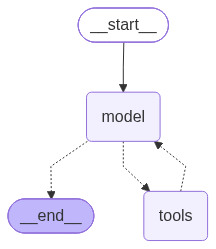

In [27]:
SUPERVISOR_PROMPT = (
    "You are the front desk of Sahyadri Digital Bank for the logged-in customer. You have no data yourself.\n"
    "1. Send each part of the customer's question to the right team: accounts, loans or cards.\n"
    "2. Each team question must be complete and self-contained: include every number and detail from the conversation.\n"
    "3. Ask several teams if needed. Combine their answers into one short reply. Never invent numbers.\n"
    "4. If no team covers something, say so."
)

supervisor = create_agent(model=llm, tools=[accounts_team, loans_team, cards_team], system_prompt=SUPERVISOR_PROMPT)
show_graph(supervisor)

The supervisor's graph looks exactly like any agent: `model` and `tools`. The specialists are hidden **inside** the tools. Run it with a trace: the supervisor's own tool calls, and indented, what each specialist did.

In [28]:
def run_supervisor(question, agent=supervisor, config=None):
    counter = CallCounter()
    config = {**(config or {}), "callbacks": [counter]}
    print("Q:", question)
    out = agent.invoke({"messages": [{"role": "user", "content": question}]}, config)
    print("A:", out["messages"][-1].content)
    print(f"   LLM calls: {counter.calls} | tokens: {counter.tokens}\n")
    return out


run_supervisor("What is my current balance?")
run_supervisor("Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%? "
               "Also, how much did I spend on shopping in September?")

Q: What is my current balance?
      [accounts] received: What is the current balance of the logged-in customer?
      [accounts] tool -> get_balance {}
A: Your current balance is Rs 35,134.18.
   LLM calls: 4 | tokens: 1087

Q: Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%? Also, how much did I spend on shopping in September?
      [accounts] received: How much did I spend on shopping in September?
      [accounts] tool -> spending_by_category {"month": "2026-09"}
      [loans] received: Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%?
      [loans] tool -> check_eligibility {"principal": 200000, "annual_rate_percent": 12, "months": 24}
A: You are eligible for another personal loan of Rs 2,00,000 for 24 months at 12%. Your monthly income is Rs 57,333.33, existing EMIs are Rs 14,087.04, and the new EMI would be Rs 9,414.69, resulting in a FOIR of 41.0%.

Additionally, you spent Rs 24,458.04 on shopping in September.
   LLM calls: 6 | toke

{'messages': [HumanMessage(content='Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%? Also, how much did I spend on shopping in September?', additional_kwargs={}, response_metadata={}, id='a46bcb2c-4cfa-4c6a-858f-771b01aba4af'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model_name': 'openai/gpt-4o-mini', 'id': 'gen-1795241594-yALNRsvY5e5V2O3FDfJE', 'created': 1795241594, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 8.715e-05, 'cost_details': {'upstream_inference_completions_cost': 4.56e-05, 'upstream_inference_prompt_cost': 4.155e-05, 'upstream_inference_cost': 8.715e-05}, 'system_fingerprint': 'fp_043e42998c'}, id='lc_run--01a1fcbc-cd26-7ef3-944d-a9744df43c7a-0', tool_calls=[{'name': 'loans_team', 'args': {'question': 'Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%?'}, 'id': 'call_lzDgwxHCmhQIApwxj5626BsA', 'type': 'tool_call'}, {'name': 'accou

Read the trace for the second question: the supervisor asked **two** teams, and each team made its own tool calls. Note the LLM calls: the supervisor calls the model at least twice (decide, then answer), and every specialist at least twice as well.

Check the numbers against Part 2: eligibility FOIR about 41%, shopping in September from `spending_by_category`.

## Part 4: Pattern B - a router graph with parallel specialists

The supervisor **decides at run time**, which costs LLM calls and can wander. A **router** is a fixed LangGraph workflow (Session 7):

1. `route` - one structured-output call picks the teams
2. **fan out** - one `Send` per chosen team: those specialists run **in parallel**
3. `synthesize` - merge the answers (no LLM call if only one team answered)

`Send(node, payload)` starts `node` with `payload` as its input. Returning a **list** of `Send`s from a conditional edge runs those nodes in the same step, in parallel. Their outputs are collected with a reducer, exactly as in Session 7 Part 3.

In [29]:
class TeamChoice(BaseModel):
    teams: list[Literal["accounts", "loans", "cards"]] = Field(
        description="Every team needed to answer the question. Usually one. Empty if no team fits.")


class DeskState(TypedDict):
    question: str
    teams: list[str]
    answers: Annotated[list[str], operator.add]     # parallel specialists append here
    reply: str


router_llm = llm.with_structured_output(TeamChoice)
SPECIALISTS = {"accounts": accounts_agent, "loans": loans_agent, "cards": cards_agent}


def route(state: DeskState) -> dict:
    choice = router_llm.invoke([
        SystemMessage("Pick the bank teams needed for this customer question. accounts: balance, transactions, "
                      "spending. loans: loans, EMIs, eligibility. cards: debit card status, limits, lost card."),
        HumanMessage(state["question"]),
    ])
    return {"teams": list(dict.fromkeys(choice.teams))}      # remove duplicates, keep order


def make_desk(name):
    def desk(state) -> dict:
        answer = ask_specialist(name, SPECIALISTS[name], state["question"])
        return {"answers": [f"{name}: {answer}"]}
    return desk

In [30]:
def fan_out(state: DeskState) -> list[Send]:
    if not state["teams"]:
        return [Send("synthesize", {"question": state["question"], "answers": []})]
    return [Send(f"{team}_desk", {"question": state["question"]}) for team in state["teams"]]

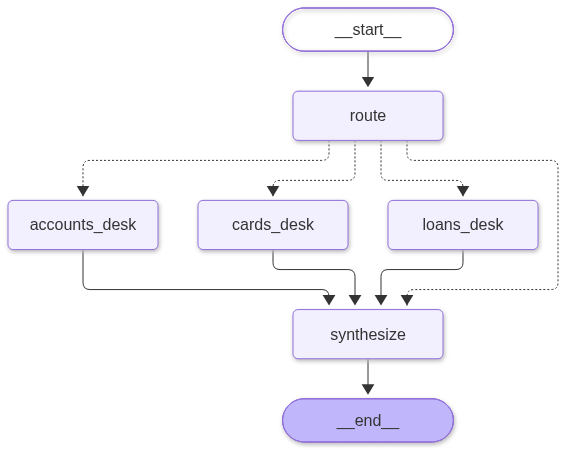

In [31]:
def synthesize(state) -> dict:
    answers = state["answers"]
    if not answers:
        return {"reply": "Sorry, I can help only with accounts, loans and cards."}
    if len(answers) == 1:                                   # one team: no extra LLM call needed
        return {"reply": answers[0].split(": ", 1)[1]}
    merged = llm.invoke([
        SystemMessage("Combine the team answers into one short reply to the customer. Keep every number exactly."),
        HumanMessage(f"Question: {state['question']}\n\nTeam answers:\n" + "\n".join(answers)),
    ])
    return {"reply": merged.content}


b = StateGraph(DeskState)
b.add_node("route", route)
for team in SPECIALISTS:
    b.add_node(f"{team}_desk", make_desk(team))
    b.add_edge(f"{team}_desk", "synthesize")
b.add_node("synthesize", synthesize)
b.add_edge(START, "route")
b.add_conditional_edges("route", fan_out, [f"{t}_desk" for t in SPECIALISTS] + ["synthesize"])
b.add_edge("synthesize", END)

router = b.compile()
show_graph(router)

`add_conditional_edges` gets the list of possible targets as its third argument, because `fan_out` returns `Send` objects instead of node names, so LangGraph cannot read the targets from a `Literal` type.

In [32]:
def run_router(question, config=None):
    counter = CallCounter()
    config = {**(config or {}), "callbacks": [counter]}
    print("Q:", question)
    start = time.time()
    out = router.invoke({"question": question}, config)
    print("teams:", out["teams"])
    print("A:", out["reply"])
    print(f"   LLM calls: {counter.calls} | tokens: {counter.tokens} | {time.time() - start:.1f} s\n")
    return out


run_router("What is my current balance?")
run_router("Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%? "
           "Also, how much did I spend on shopping in September?")
run_router("What will the weather be in Pune tomorrow?")

Q: What is my current balance?
      [accounts] received: What is my current balance?
      [accounts] tool -> get_balance {}
teams: ['accounts']
A: Your current savings balance is Rs 35,134.18.
   LLM calls: 3 | tokens: 618 | 3.3 s

Q: Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%? Also, how much did I spend on shopping in September?
      [loans] received: Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%? Also, how much did I spend on shopping in September?
      [loans] tool -> check_eligibility {"principal": 200000, "annual_rate_percent": 12, "months": 24}
      [loans] tool -> my_loans {}
      [accounts] received: Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%? Also, how much did I spend on shopping in September?
      [accounts] tool -> get_balance {}
      [accounts] tool -> spending_by_category {"month": "2026-09"}
teams: ['loans', 'accounts']
A: You are eligible for a personal loan of Rs 2,00,000 for 24 mo

{'question': 'What will the weather be in Pune tomorrow?',
 'teams': [],
 'answers': [],
 'reply': 'Sorry, I can help only with accounts, loans and cards.'}

For the two-team question, the `[loans]` and `[accounts]` traces may print **interleaved**: they ran at the same time. The off-topic question is answered by `synthesize` with no specialist call at all.

## Part 5: Single agent vs supervisor vs router

Same questions, three designs. We measure LLM calls, tokens and seconds. Specialist traces are switched off here to keep the output short.

In [33]:
single_agent = create_agent(model=llm, tools=ALL_TOOLS,
    system_prompt="You are the Sahyadri Digital Bank assistant for the logged-in customer. " + RULES)

QUESTIONS = [
    "What is my current balance?",
    "Can I afford another personal loan of Rs 2,00,000 for 24 months at 12%? Also, how much did I spend on shopping in September?",
    "Is international usage enabled on my debit card, and what is my daily ATM limit?",
]


def answer_single(question, config):
    return single_agent.invoke({"messages": [{"role": "user", "content": question}]}, config)["messages"][-1].content


def answer_supervisor(question, config):
    return supervisor.invoke({"messages": [{"role": "user", "content": question}]}, config)["messages"][-1].content


def answer_router(question, config):
    return router.invoke({"question": question}, config)["reply"]


SHOW_TRACE = False

rows = []
for qi, question in enumerate(QUESTIONS, start=1):
    for design, fn in [("single agent", answer_single), ("supervisor", answer_supervisor), ("router", answer_router)]:
        counter = CallCounter()
        start = time.time()
        reply = fn(question, {"callbacks": [counter]})
        rows.append({"question": qi, "design": design, "llm_calls": counter.calls,
                     "tokens": counter.tokens, "seconds": round(time.time() - start, 1), "reply": reply[:80]})

SHOW_TRACE = True

results = pd.DataFrame(rows)
results

,question,design,llm_calls,tokens,seconds,reply
0,1,single agent,2,966,2.0,"Your current balance is Rs 35,134.18."
1,1,supervisor,4,1087,4.4,"Your current balance is Rs 35,134.18."
2,1,router,3,619,3.0,"Your current savings account balance is Rs 35,..."
3,2,single agent,2,1291,3.8,You are eligible for the personal loan of Rs 2...
4,2,supervisor,6,2134,5.9,"You can afford another personal loan of Rs 2,0..."
5,2,router,6,2055,5.6,"You are eligible for a personal loan of Rs 2,0..."
6,3,single agent,2,1100,2.0,"International usage on your debit card is OFF,..."
7,3,supervisor,6,1496,5.0,International usage is currently OFF on your d...
8,3,router,3,668,3.3,"Your debit card (ending 4417) is active, with ..."


In [34]:
results.groupby("design")[["llm_calls", "tokens", "seconds"]].sum().sort_values("llm_calls")

,llm_calls,tokens,seconds
design,,,
single agent,6,3357,7.8
router,12,3342,11.9
supervisor,16,4717,15.3


Typical result: the **single agent** is cheapest, the **router** is in between (one routing call, specialists in parallel), the **supervisor** costs the most (it calls the model before and after the specialists). With only 8 tools, the single agent is the right choice for this bank. The other designs pay off when tools, rules and teams grow.

| | Single agent | Supervisor (Pattern A) | Router (Pattern B) |
|---|---|---|---|
| Who decides the path | the agent | the supervisor LLM, at run time | one routing call, then fixed |
| LLM calls | fewest | most | in between |
| Parallel specialists | - | possible, not guaranteed | yes, with `Send` |
| Follow-up questions, multi-step plans | good | best | weak (one shot) |
| Predictable, testable | medium | lowest | highest |

## Part 6: Context between agents - what a specialist actually sees

A specialist receives **only the question string** the supervisor writes. It does not see the conversation. That is good (short prompts, no leaking of unrelated details) and dangerous (missing context).

Give the supervisor memory (Session 7) and ask a follow-up that only makes sense with the history:

In [ ]:
memory_supervisor = create_agent(model=llm, tools=[accounts_team, loans_team, cards_team],
                                 system_prompt=SUPERVISOR_PROMPT, checkpointer=InMemorySaver())
thread = {"configurable": {"thread_id": "riya-desk-1"}}

run_supervisor("I am thinking of a personal loan of Rs 2,00,000 for 24 months at 12%. What would the EMI be?",
               agent=memory_supervisor, config=thread)
run_supervisor("Can I afford it?", agent=memory_supervisor, config=thread)

Look at the line `[loans] received: ...` for the second turn. A good supervisor rewrites "Can I afford it?" into a **self-contained** question with the amount, rate and tenure. If it forwards "Can I afford it?" as it is, the loans specialist cannot answer.

That is why rule 2 of `SUPERVISOR_PROMPT` and the tool's argument description both say *complete, self-contained question*. The interface between agents is a prompt, so it needs the same care as a tool docstring.

| Option | What the specialist sees | Trade-off |
|---|---|---|
| Pass a rewritten question (ours) | one string | short, private; depends on a good rewrite |
| Pass the full message history | everything | robust; more tokens, every agent sees everything |
| Shared state in one graph | the keys you choose | most control; more code |

| AutoGen message | LangChain equivalent |
|---|---|
| `TextMessage` from `user` | `HumanMessage` |
| `ToolCallRequestEvent` | `AIMessage` with `tool_calls` |
| `ToolCallExecutionEvent` | `ToolMessage` |
| final `TextMessage` from the agent | final `AIMessage` |

## Part 9: LangGraph or AutoGen?

| | LangChain / LangGraph | AutoGen AgentChat |
|---|---|---|
| Core idea | a graph of steps over a shared state | agents exchanging messages |
| Control flow | explicit: nodes, edges, routing functions | team types decide who speaks next |
| Memory and resume | checkpointers, thread_id, interrupts | team state can be saved and loaded |
| Human approval | `interrupt`, middleware | a `UserProxyAgent` in the team |
| Multi-agent patterns | supervisor as tools, router with `Send`, custom graphs | RoundRobin, Selector (LLM picks the speaker), Swarm (handoffs) |
| Style | sync or async | async |
| Status | actively developed | maintenance mode; successor: Microsoft Agent Framework |
| Good fit | production workflows that need control and auditability | quick multi-agent conversations and prototypes |

The concepts are the same everywhere: **tools, a loop, state, termination, human approval**. Learn them once; frameworks are dialects.

## Exercises

1. **Easy** - Add an **investments** specialist with one tool `sip_future_value(monthly_amount, annual_return_percent, years)` (future value of a monthly SIP: `P * ((1 + r)**n - 1) / r * (1 + r)` with `r` the monthly rate and `n` the number of months). Add it to the supervisor as `investments_team` and ask: *"If I invest Rs 5,000 every month for 10 years at 12%, how much will I have, and what is my balance today?"*
2. **Medium** - Test the router: write 8 questions with the expected list of teams (include one off-topic question and two that need two teams). Run only `route` (no specialists) on each and print the accuracy. Change the routing prompt to fix any misses.